In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram
sys.path.append("../")
from analysis import System
import gc

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [21]:
masks = ["no", "0.38", "0.54", "0.70"]
norm = ["52mW_Pin", "1mW_Pout"]
voltages = ["10"]
# for i in np.linspace(0, 10, 21):
#     if 2 * i % 2 == 0:
#         voltages.append(str(int(i)))
#     else:
#         voltages.append(str(i))
# l = System("michelson", [f"../../data/20261017/{k}mask_{w}_{j}V/iter_{i}.tdms" for w in norm for k in masks for j in voltages for i in range(0, 20) if ((k != "no" and k != "0.70") or (k == "no" and (j == "0" or j == "10" or j == "9.5" or j == "9") and w != "1mW_Pout") or (k == "0.70" and w != "52mW_Pin"))], set_data = True, channel = "X")
l = System("michelson", [f"../../data/20261017/{k}mask_{norm[0]}_{j}V/iter_{i}.tdms" 
    if k != "0.70"
    else f"../../data/20261017/{k}mask_{norm[1]}_{j}V/iter_{i}.tdms" 
    if k == "0.70" 
    else None
    for k in masks 
    for j in voltages 
    for i in range(0, 20)], set_data = True, channel = "X")

SNR in 238 Hz: 20.1 dB (+0.2 / -0.3 dB)
SNR in 238 Hz: 17.0 dB (+0.2 / -0.2 dB)
SNR in 238 Hz: 17.9 dB (+0.2 / -0.2 dB)
SNR in 238 Hz: 12.8 dB (+0.4 / -0.4 dB)


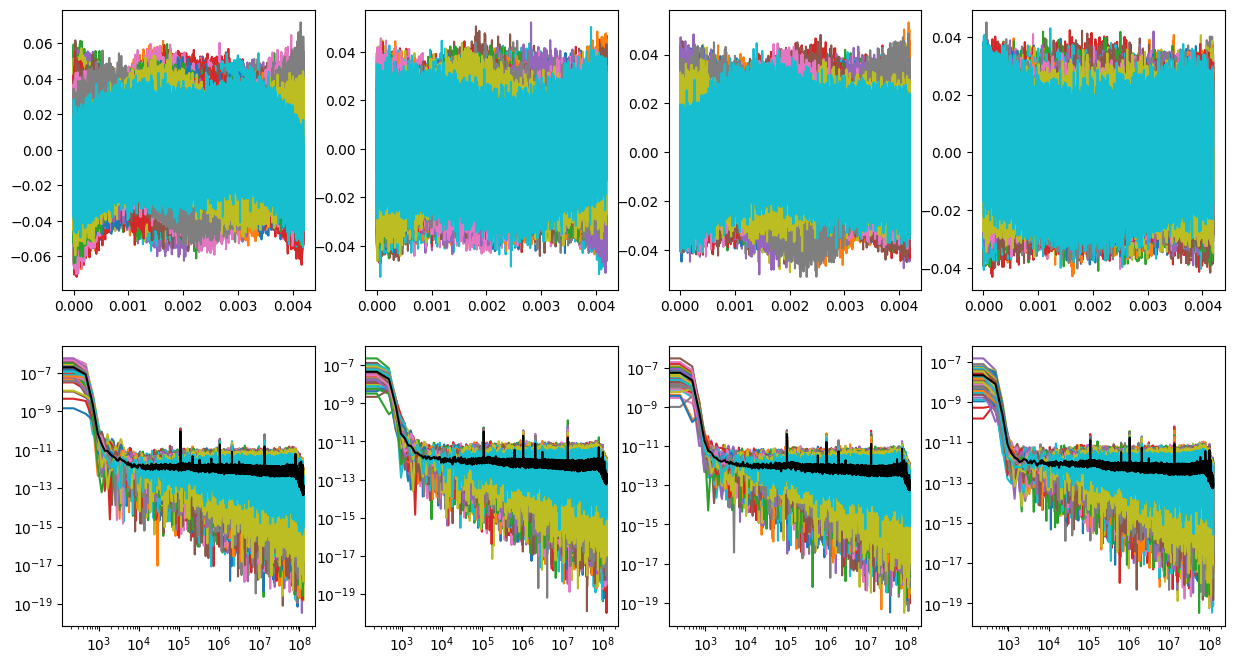

87451

In [22]:
fig, ax = plt.subplots(2, 4, figsize = (15, 8))
freq = 109e3
for i in range(0, 80):
    l.set_data(ind = i)
    l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
    ax[0][i // 20].plot(l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x)
    ax[0][i // 20].plot(l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x)
    f, p0 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    _, p1 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    ax[1][i // 20].loglog(f, p0)
    ax[1][i // 20].loglog(f, p1)
    if i % 20 == 0:
        P = []
    p = np.array((p0 + p1) / 2)
    ax[1][i // 20].loglog(f, p)
    P.append(p)
    if i % 20 == 19:
        P = np.array(P)
        Pm = np.mean(P, axis = 0)
        std = np.std(P, axis = 0) 
        ax[1][i // 20].loglog(f, Pm, c = "k")

        df = f[1] - f[0]
        ix = np.argmin(np.abs(f - freq))
        ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
        pk = slice(ix - 4, ix + 5)
        nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
        assert nb.sum() > 50, f"only {nb.sum()} noise bins"
        Sn = np.mean(Pm[nb])
        Psig = np.sum(Pm[pk] - Sn) * df
        if Psig <= 0:
            print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
        else:
            snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
            m, e = np.mean(snrs), np.std(snrs, ddof = 1) / np.sqrt(len(snrs))
            print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
    
plt.show()
plt.close()
gc.collect()

In [14]:
l = System("michelson", np.sort([f"{path}{f}/iter_{i}.tdms" for f in os.listdir(path) if os.path.isdir(os.path.join(path, f)) for i in range(0, 10)]), set_data = True, channel = "X")

In [54]:
voltages = []
for i in np.linspace(0, 10, 21):
    if 2 * i % 2 == 0:
        voltages.append(str(int(i)))
    else:
        voltages.append(str(i))
print(voltages)

['0', '0.5', '1', '1.5', '2', '2.5', '3', '3.5', '4', '4.5', '5', '5.5', '6', '6.5', '7', '7.5', '8', '8.5', '9', '9.5', '10']


In [72]:
snr38 = []
snr54 = []
snr70 = []
snrno = []

# fig, ax = plt.subplots(2, 4, figsize = (15, 8))
freq = 109e3
for v in voltages:
    V = l.get_df()[np.array([f"Pout_{v}V" in i or ("0.70" in i and f"Pin_{v}V" in i) for i in l.get_df()])]
    for i in range(len(V)):
        idx = np.where(l.get_df() == V[i])[0][0]
        l.set_data(ind = idx)
        d = l.get_data()[idx]
        d.apply("detrend", mode = "linear", inplace = True)
        # ax[0][i // 10].plot(d.collection[0].t, d.collection[0].x)
        # ax[0][i // 10].plot(d.collection[1].t, d.collection[1].x)
        f, p0 = periodogram(d.collection[0].x, d.r, window = "hann", detrend = "linear")
        _, p1 = periodogram(d.collection[1].x, d.r, window = "hann", detrend = "linear")
        # ax[1][i // 10].loglog(f, p0)
        # ax[1][i // 10].loglog(f, p1)
        if i % 10 == 0:
            P = []
        p = np.array((p0 + p1) / 2)
        # ax[1][i // 10].loglog(f, p)
        P.append(p)
        if i % 10 == 9:
            P = np.array(P)
            Pm = np.mean(P, axis = 0)
            std = np.std(P, axis = 0) 
            # ax[1][i // 10].loglog(f, Pm, c = "k")
    
            df = f[1] - f[0]
            ix = np.argmin(np.abs(f - freq))
            ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
            pk = slice(ix - 4, ix + 5)
            nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
            assert nb.sum() > 50, f"only {nb.sum()} noise bins"
            Sn = np.mean(Pm[nb])
            Psig = np.sum(Pm[pk] - Sn) * df
            if Psig <= 0:
                print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
            else:
                snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
                m, e = np.mean(snrs), np.std(snrs, ddof = 1) / np.sqrt(len(snrs))
                print(f"SNR in {df:.0f} Hz: {10 * np.log10(Psig / (Sn * df)):.1f} dB,  C/N0: {10 * np.log10(Psig / Sn):.1f} dB-Hz")
                print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
            if i // 10 == 0:
                # snr38.append(10 * np.log10(m))
                snr38.append(10 * np.log10(Psig / Sn))
            if i // 10 == 1:
                # snr54.append(10 * np.log10(m))
                snr54.append(10 * np.log10(Psig / Sn))
            if i // 10 == 2:
                # snr70.append(10 * np.log10(m))
                snr70.append(10 * np.log10(Psig / Sn))
            if i // 10 == 3:
                # snrno.append(10 * np.log10(m))
                snrno.append(10 * np.log10(Psig / Sn))
            print(l.get_df()[idx])
            print()
            # ax[0][i // 10].set_title(l.get_df()[idx][20:26])
    
# plt.show()
# plt.close()
gc.collect()

SNR in 15 Hz: -1.6 dB,  C/N0: 10.3 dB-Hz
SNR in 15 Hz: -1.9 dB (+4.6 / -nan dB)
../../data/20261019/0.38mmMask_1mW_Pout_0V/iter_9.tdms

no detection: Psig < 3.1851863908083735e-09 V^2
../../data/20261019/0.54mmMask_1mW_Pout_0V/iter_9.tdms

SNR in 15 Hz: 0.5 dB,  C/N0: 12.3 dB-Hz
SNR in 15 Hz: 0.8 dB (+3.3 / -nan dB)
../../data/20261019/0.70mmMask_52mW_Pin_0V/iter_9.tdms



/tmp/ipykernel_12009/2154114279.py:46: RuntimeWarning: invalid value encountered in log10
  print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
/tmp/ipykernel_12009/2154114279.py:52: RuntimeWarning: invalid value encountered in log10
  snr54.append(10 * np.log10(Psig / Sn))


no detection: Psig < 3.8891061626061226e-09 V^2
../../data/20261019/noMask_1mW_Pout_0V/iter_9.tdms

SNR in 15 Hz: 3.0 dB,  C/N0: 14.8 dB-Hz
SNR in 15 Hz: 2.9 dB (+1.9 / -3.4 dB)
../../data/20261019/0.38mmMask_1mW_Pout_0.5V/iter_9.tdms

no detection: Psig < 3.527202722077527e-09 V^2
../../data/20261019/0.54mmMask_1mW_Pout_0.5V/iter_9.tdms



/tmp/ipykernel_12009/2154114279.py:58: RuntimeWarning: invalid value encountered in log10
  snrno.append(10 * np.log10(Psig / Sn))


SNR in 15 Hz: -0.8 dB,  C/N0: 11.1 dB-Hz
SNR in 15 Hz: -1.0 dB (+2.7 / -9.3 dB)
../../data/20261019/0.70mmMask_52mW_Pin_0.5V/iter_9.tdms

SNR in 15 Hz: -3.4 dB,  C/N0: 8.5 dB-Hz
SNR in 15 Hz: -3.9 dB (+5.3 / -nan dB)
../../data/20261019/noMask_1mW_Pout_0.5V/iter_9.tdms

SNR in 15 Hz: 2.4 dB,  C/N0: 14.2 dB-Hz
SNR in 15 Hz: 2.4 dB (+2.6 / -7.7 dB)
../../data/20261019/0.38mmMask_1mW_Pout_1V/iter_9.tdms

no detection: Psig < 3.464097455624844e-09 V^2
../../data/20261019/0.54mmMask_1mW_Pout_1V/iter_9.tdms

no detection: Psig < 3.56779383724068e-09 V^2
../../data/20261019/0.70mmMask_52mW_Pin_1V/iter_9.tdms

no detection: Psig < 3.8125437786078075e-09 V^2
../../data/20261019/noMask_1mW_Pout_1V/iter_9.tdms



/tmp/ipykernel_12009/2154114279.py:55: RuntimeWarning: invalid value encountered in log10
  snr70.append(10 * np.log10(Psig / Sn))


SNR in 15 Hz: 2.4 dB,  C/N0: 14.2 dB-Hz
SNR in 15 Hz: 2.6 dB (+2.4 / -5.9 dB)
../../data/20261019/0.38mmMask_1mW_Pout_1.5V/iter_9.tdms

SNR in 15 Hz: 2.7 dB,  C/N0: 14.5 dB-Hz
SNR in 15 Hz: 2.6 dB (+2.2 / -4.6 dB)
../../data/20261019/0.54mmMask_1mW_Pout_1.5V/iter_9.tdms

SNR in 15 Hz: 4.2 dB,  C/N0: 16.1 dB-Hz
SNR in 15 Hz: 4.6 dB (+1.7 / -2.8 dB)
../../data/20261019/0.70mmMask_52mW_Pin_1.5V/iter_9.tdms

SNR in 15 Hz: 5.5 dB,  C/N0: 17.3 dB-Hz
SNR in 15 Hz: 5.5 dB (+1.3 / -1.9 dB)
../../data/20261019/noMask_1mW_Pout_1.5V/iter_9.tdms

SNR in 15 Hz: 7.6 dB,  C/N0: 19.5 dB-Hz
SNR in 15 Hz: 7.6 dB (+1.2 / -1.7 dB)
../../data/20261019/0.38mmMask_1mW_Pout_2V/iter_9.tdms

SNR in 15 Hz: 5.6 dB,  C/N0: 17.5 dB-Hz
SNR in 15 Hz: 5.8 dB (+1.7 / -2.8 dB)
../../data/20261019/0.54mmMask_1mW_Pout_2V/iter_9.tdms

SNR in 15 Hz: 3.8 dB,  C/N0: 15.6 dB-Hz
SNR in 15 Hz: 3.9 dB (+1.3 / -1.9 dB)
../../data/20261019/0.70mmMask_52mW_Pin_2V/iter_9.tdms

SNR in 15 Hz: 7.2 dB,  C/N0: 19.0 dB-Hz
SNR in 15 Hz: 7.2 

276

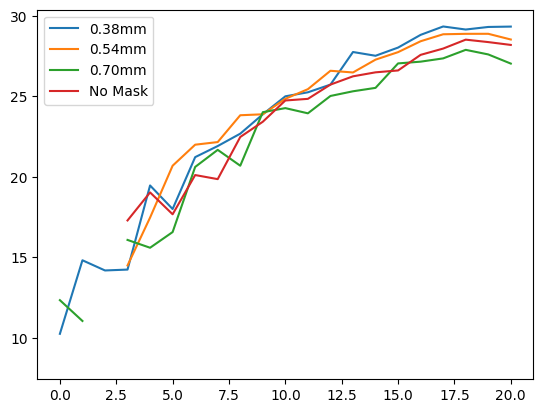

In [74]:
plt.plot(snr38, label = "0.38mm")
plt.plot(snr54, label = "0.54mm")
plt.plot(snr70, label = "0.70mm")
plt.plot(snrno, label = "No Mask")
plt.legend()
plt.show()